# PartB - Fig. XX  (a, b; portrait): glacier model differences in steady-state mass and in climate scenario sensitivity

Difference of every glacier model to the median model in every RGI region (Global on top, then the regions sorted by their 2020 glacier mass as in GMIP3-comm Fig. 2), for the temperature bin 2.0°C to 4.0°C. One row per glacier model: **dot = median** over the 31 climate scenarios, **line = likely range** (17th to 83rd percentile of the 31 climate scenarios). The figure is made for a width of 12 cm.
- `a`: difference of the steady-state mass to the median model
- `b`: change of that difference relative to the climate of 1995-2014 (climate scenario sensitivity)

We also looked at the other temperature bins, but don't show them in the manuscript.

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [13]:
fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
temp_bin = [2.0, 4.0]            # global warming bin in °C
# temp_bin = [4.0, 7.0]            # global warming bin in °C
# temp_bin = [-0.1, 2.0]            # global warming bin in °C

likely_range = [17, 83]          # percentiles over the climate scenarios
ref_period = '1995-2014_hist'    # reference climate for the climate scenario sensitivity (Fig. 2)

# panels from left to right: 'a' (steady-state mass), 'b' (climate scenario sensitivity); ['b] 
panel_order = ['a', 'b']

# difference to which median?
#  'all_models': median of all glacier models in the region (= the existing 'delta ... to median model' columns, as in the first versions of Fig. 1 and 2)
#  'global4': median of the four global models only (the same models in every region)
reference = 'all_models'

fig_width_cm, fig_height_cm = 11.5, 19     # two-column figure of the journal, needs to be a bit taller than the magnitude figure
x_lims = {'a': (-40, 65), 'b': (-65, 50)}      # % points
x_ticks = {'a': np.arange(-40, 61, 20), 'b': np.arange(-60, 41, 20)}
fs = 6                                   # smallest font size in the figure

fig_dir = 'figures_partB/glacier_model_ss_differences/'
os.makedirs(fig_dir, exist_ok=True)

## Names, colours and order of the regions

In [14]:
reg_names = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}
# names with a line break where a name is long
reg_names_lines = dict(reg_names)
reg_names_lines.update({'05': 'Greenland\nPeriphery', '07': 'Svalbard &\nJan Mayen', '12': 'Caucasus &\nMiddle East',
                        '19': 'Subantarctic &\nAntarctic Islands'})

# Global on top, then sorted by the 2020 glacier mass (descending) as in Fig. 2 of GMIP3-comm
reg_order = ['All', '19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']

global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv file, all others are the same
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}

## 1. Prepare the data

In [15]:
pd_ss = pd.read_csv(fn_steady_state, index_col=0)
pd_ss['model'] = pd_ss.model_author.replace(model_names_csv)
pd_ss['reg'] = pd_ss.rgi_reg.replace({'Global': 'All'})

rc = 'relative volume change (in %)'
dc = 'delta relative volume change (in %, to median model)'
dc2 = 'delta relative volume change (in %, to median model, relative to ref period )'

# difference of every model to the reference (a) and its change relative to the reference climate (b)
if reference == 'all_models':
    pd_ss['a'] = pd_ss[dc]
    pd_ss['b'] = pd_ss[dc2]
else:
    ref = pd_ss.loc[pd_ss.model.isin(global_models)].groupby(['reg', 'gcm', 'period_scenario'])[rc].median()
    pd_ss = pd_ss.join(ref.rename('ref'), on=['reg', 'gcm', 'period_scenario'])
    pd_ss['a'] = pd_ss[rc] - pd_ss['ref']
    d_ref_period = pd_ss.loc[pd_ss.period_scenario == ref_period].set_index(['reg', 'model', 'gcm'])['a']
    pd_ss = pd_ss.join(d_ref_period.rename('a_ref_period'), on=['reg', 'model', 'gcm'])
    pd_ss['b'] = pd_ss['a'] - pd_ss['a_ref_period']

pd_bin = pd_ss.loc[(pd_ss.temp_ch_ipcc >= temp_bin[0]) & (pd_ss.temp_ch_ipcc <= temp_bin[1])]
n_scen = len(pd_bin.groupby(['gcm', 'period_scenario']))
if temp_bin[1] == 4.0:
    np.testing.assert_allclose(len(pd_bin.groupby(['gcm', 'period_scenario'])), 31)


# median and likely range over the climate scenarios
pd_sums = {}
for p in ['a', 'b']:
    g = pd_bin.groupby(['reg', 'model'])[p]
    pd_sums[p] = pd.DataFrame({'med': g.median(), 'lo': g.quantile(likely_range[0] / 100),
                               'hi': g.quantile(likely_range[1] / 100)})
    print(p, pd_sums[p].shape, '| range of the likely ranges:', np.round(pd_sums[p].lo.min(),1),
          'to', np.round(pd_sums[p].hi.max(),1))

a (96, 3) | range of the likely ranges: -33.4 to 60.8
b (96, 3) | range of the likely ranges: -61.0 to 46.8


**Check:** the order of the regions. The 2020 volume in the csv file (volume divided by relative volume change) gives the same order as GMIP3-comm Fig. 2:

In [16]:
pd_chk = pd_ss.loc[pd_ss.reg != 'All'].copy()
pd_chk['v0'] = pd_chk.volume_m3 / (pd_chk[rc] / 100)
v0_reg = pd_chk.groupby('reg').v0.median()
print('order from the csv file  :', list(v0_reg.sort_values(ascending=False).index))
print('order used in the figure :', reg_order[1:])
print('share of the global volume (%):', (100 * v0_reg / v0_reg.sum()).round(1).reindex(reg_order[1:]).to_dict())

order from the csv file  : ['19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']
order used in the figure : ['19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']
share of the global volume (%): {'19': 30.1, '03': 18.1, '01': 11.8, '05': 9.8, '09': 9.4, '04': 5.2, '07': 4.8, '17': 3.2, '06': 2.3, '13': 2.0, '14': 1.8, '02': 0.6, '15': 0.5, '08': 0.2, '10': 0.1, '11': 0.1, '16': 0.1, '18': 0.0, '12': 0.0}


## 2. The figure

In [17]:
x_ticks

{'a': array([-40, -20,   0,  20,  40,  60]),
 'b': array([-60, -40, -20,   0,  20,  40])}

31 climate scenarios between 2.0°C and 4.0°C global warming


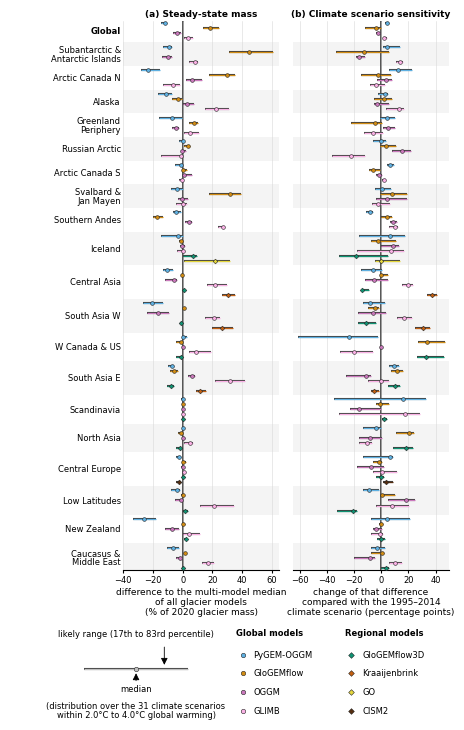

In [25]:
import matplotlib.patheffects as pe      # thin dark outline around the likely-range lines

n_panels = len(panel_order)
if n_panels == 1:
    boxes = [(0.285, 0.70)]
else:
    boxes = [(0.27, 0.345), (0.645, 0.345)]      # (left, width) of the panels
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))

# one row per glacier model, the four global models first and then the regional models, with a gap between the regions
gap = 0.7
rows = []
y = 0
reg_centres = []
reg_spans = []
for i, reg in enumerate(reg_order):
    models_reg = [m for m in global_models + regional_models if (reg, m) in pd_sums['a'].index]
    reg_spans.append((y - 0.5 - gap / 2, y + len(models_reg) - 0.5 + gap / 2, i))
    for k, m in enumerate(models_reg):
        rows.append((reg, m, y + k))
    reg_centres.append((y + (len(models_reg) - 1) / 2, reg))
    y = y + len(models_reg) + gap
y_max = y - gap - 0.5

titles = {'a': 'Steady-state mass', 'b': 'Climate scenario sensitivity'}
if reference == 'all_models':
    xlabels = {'a': 'difference to the multi-model median\nof all glacier models\n(% of 2020 glacier mass)',
               'b': 'change of that difference\ncompared with the 1995–2014\nclimate scenario (percentage points)'}
else:
    xlabels = {'a': 'difference to the\nmulti-model median\n(% of 2020 glacier mass)',
               'b': 'change of that difference\ncompared with the 1995–2014\nclimate scenario (percentage points)'}

axes = []
for i_p, p in enumerate(panel_order):
    #ax = fig.add_axes([boxes[i_p][0], 0.185, boxes[i_p][1], 0.745])
    ax = fig.add_axes([boxes[i_p][0], 0.205, boxes[i_p][1], 0.735])   # bottom raised from 0.185 to leave room for the three-line x-labels
    axes.append(ax)
    for y_lo, y_hi, i in reg_spans:    # light background for every second region
        if i % 2 == 1:
            ax.axhspan(y_lo, y_hi, color='0.955', lw=0, zorder=0)
    for reg, m, y_row in rows:
        r = pd_sums[p].loc[(reg, m)]
        marker = 'o' if m in global_models else 'D'
        ax.plot([r.lo, r.hi], [y_row] * 2, color=dict_model_col[m], lw=0.9, solid_capstyle='butt', zorder=2,
                path_effects=[pe.Stroke(linewidth=1.5, foreground='0.25'), pe.Normal()])
        ax.plot([r.med], [y_row], marker, ms=2.7 if marker == 'o' else 2.4,
                mfc=dict_model_col[m], mec='0.15', mew=0.4, zorder=3)
    ax.set_ylim(y_max, -0.5)
    ax.set_xlim(*x_lims[p])
    ax.axvline(0, color='0.15', lw=1.1, zorder=1)
    ax.set_yticks([])
    ax.set_xticks(x_ticks[p])
    ax.tick_params(axis='x', labelsize=fs, length=2, pad=1.5)
    ax.grid(axis='x', color='0.85', lw=0.4, zorder=0)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.set_xlabel(xlabels[p], fontsize=fs + 0.5, labelpad=2)
    if n_panels > 1:
        ax.set_title(f'({chr(97 + i_p)}) {titles[p]}', fontsize=fs + 0.5, fontweight='bold', pad=3)

# names of the regions (without the RGI region numbers)
for y_c, reg in reg_centres:
    name = reg_names_lines[reg]
    axes[0].text(-0.015, y_c, name, transform=axes[0].get_yaxis_transform(), ha='right', va='center',
                 fontsize=fs, fontweight='bold' if reg == 'All' else 'normal', linespacing=0.95)

# which climate scenarios?
#fig.text(0.5, 0.993, f'{n_scen} climate scenarios between {temp_bin[0]:.1f}\u00b0C and {temp_bin[1]:.1f}\u00b0C global warming',
#         fontsize=fs + 0.5, ha='center', va='top')
print( f'{n_scen} climate scenarios between {temp_bin[0]:.1f}\u00b0C and {temp_bin[1]:.1f}\u00b0C global warming')

# legend: dummy row with arrows, and the model names with their group as subtitle
ax_leg = fig.add_axes([0.02, 0.005, 0.96, 0.125])
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)
ax_leg.axis('off')
arrow = dict(arrowstyle='-|>', color='k', lw=0.6, shrinkA=0, shrinkB=0)

ax_leg.plot([0.17, 0.41], [0.55, 0.55], color='0.75', lw=0.9, solid_capstyle='butt',
            path_effects=[pe.Stroke(linewidth=1.5, foreground='0.25'), pe.Normal()])     # dummy likely range
ax_leg.plot([0.29], [0.55], 'o', ms=3.2, mfc='0.75', mec='0.15', mew=0.4)                  # dummy median
ax_leg.text(0.29, 0.97, 'likely range (17th to 83rd percentile)', fontsize=fs, ha='center', va='top')
ax_leg.annotate('', xy=(0.355, 0.59), xytext=(0.355, 0.78), arrowprops=arrow)
ax_leg.text(0.29, 0.33, 'median', fontsize=fs, ha='center', va='center')
ax_leg.annotate('', xy=(0.29, 0.50), xytext=(0.29, 0.42), arrowprops=arrow)
ax_leg.text(0.29, 0.10, f'(distribution over the {n_scen} climate scenarios\nwithin {temp_bin[0]:.1f}\u00b0C to {temp_bin[1]:.1f}\u00b0C global warming)',
            fontsize=fs, ha='center', va='center', linespacing=1.0)

ax_leg.text(0.52, 0.93, 'Global models', fontsize=fs, fontweight='bold', va='center')
ax_leg.text(0.77, 0.93, 'Regional models', fontsize=fs, fontweight='bold', va='center')
for k, m in enumerate(global_models):
    ax_leg.plot([0.535], [0.70 - 0.20 * k], 'o', ms=3.2, mfc=dict_model_col[m], mec='0.15', mew=0.4)
    ax_leg.text(0.56, 0.70 - 0.20 * k, m, fontsize=fs, va='center')
for k, m in enumerate(regional_models):
    ax_leg.plot([0.785], [0.70 - 0.20 * k], 'D', ms=2.9, mfc=dict_model_col[m], mec='0.15', mew=0.4)
    ax_leg.text(0.81, 0.70 - 0.20 * k, m, fontsize=fs, va='center')

fn_out = f'{fig_dir}/manuscript_v0_steady_state_glacier_model_differences_portrait_{"_".join(panel_order)}_{reference}_temp_bin_{temp_bin[0]}_{temp_bin[1]}'
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')
plt.show()

## Suggested caption (LaTeX)

```latex
\caption{Glacier model differences in the steady-state mass (a) and in the climate scenario sensitivity (b) for global
warming levels between 2.0$^\circ$C and 4.0$^\circ$C (31 climate scenarios). For each glacier model and RGI region (sorted by
their 2020 glacier mass, Global on top), (a) shows the difference of the steady-state mass (in \% points of the 2020 mass)
to the median of all glacier models in the region, and (b) the change of this difference relative to the climate of
1995--2014. Global refers to the four global models. Dots show the median over the 31 climate scenarios, lines the likely
range (17th to 83rd percentile). Regional models are only available for some regions.}
```